
# CLUSTERING ANALYSIS



# Clustering Analysis – East-West Airlines
### Algorithms: K-Means | Hierarchical | DBSCAN



## 1. Import Libraries


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
%matplotlib inline
print("Libraries imported successfully!")

Libraries imported successfully!



## 2. Load Dataset


In [39]:
df_raw = pd.read_excel('EastWestAirlines.xlsx', sheet_name=1)

print(f"Shape: {df_raw.shape}")
print(f"\nColumns: {df_raw.columns.tolist()}")
print(f"\nFirst 5 rows:")
df_raw.head()

Shape: (3999, 12)

Columns: ['ID#', 'Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll', 'Award?']

First 5 rows:


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [40]:
print("Data Types:")
print(df_raw.dtypes)
print("\nSummary Statistics:")
df_raw.describe().round(2)

Data Types:
ID#                  int64
Balance              int64
Qual_miles           int64
cc1_miles            int64
cc2_miles            int64
cc3_miles            int64
Bonus_miles          int64
Bonus_trans          int64
Flight_miles_12mo    int64
Flight_trans_12      int64
Days_since_enroll    int64
Award?               int64
dtype: object

Summary Statistics:


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
count,3999.00,3999.00,3999.00,3999.00,3999.00,3999.00,3999.00,3999.0,3999.00,3999.00,3999.00,3999.00
mean,2014.82,73601.33,144.11,2.06,1.01,1.01,17144.85,11.6,460.06,1.37,4118.56,0.37
std,1160.76,100775.66,773.66,1.38,0.15,0.20,24150.97,9.6,1400.21,3.79,2065.13,0.48
min,1.00,0.00,0.00,1.00,1.00,1.00,0.00,0.0,0.00,0.00,2.00,0.00
25%,1010.50,18527.50,0.00,1.00,1.00,1.00,1250.00,3.0,0.00,0.00,2330.00,0.00
50%,2016.00,43097.00,0.00,1.00,1.00,1.00,7171.00,12.0,0.00,0.00,4096.00,0.00
75%,3020.50,92404.00,0.00,3.00,1.00,1.00,23800.50,17.0,311.00,1.00,5790.50,1.00
max,4021.00,1704838.00,11148.00,5.00,3.00,5.00,263685.00,86.0,30817.00,53.00,8296.00,1.00


In [41]:
print("Missing Values:")
print(df_raw.isnull().sum())

# Drop ID column
df = df_raw.drop(columns=['ID#'])
print("\nID column dropped. Ready for EDA.")

Missing Values:
ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64

ID column dropped. Ready for EDA.



## 3. Exploratory Data Analysis (EDA)



### 3.1 Feature Distributions


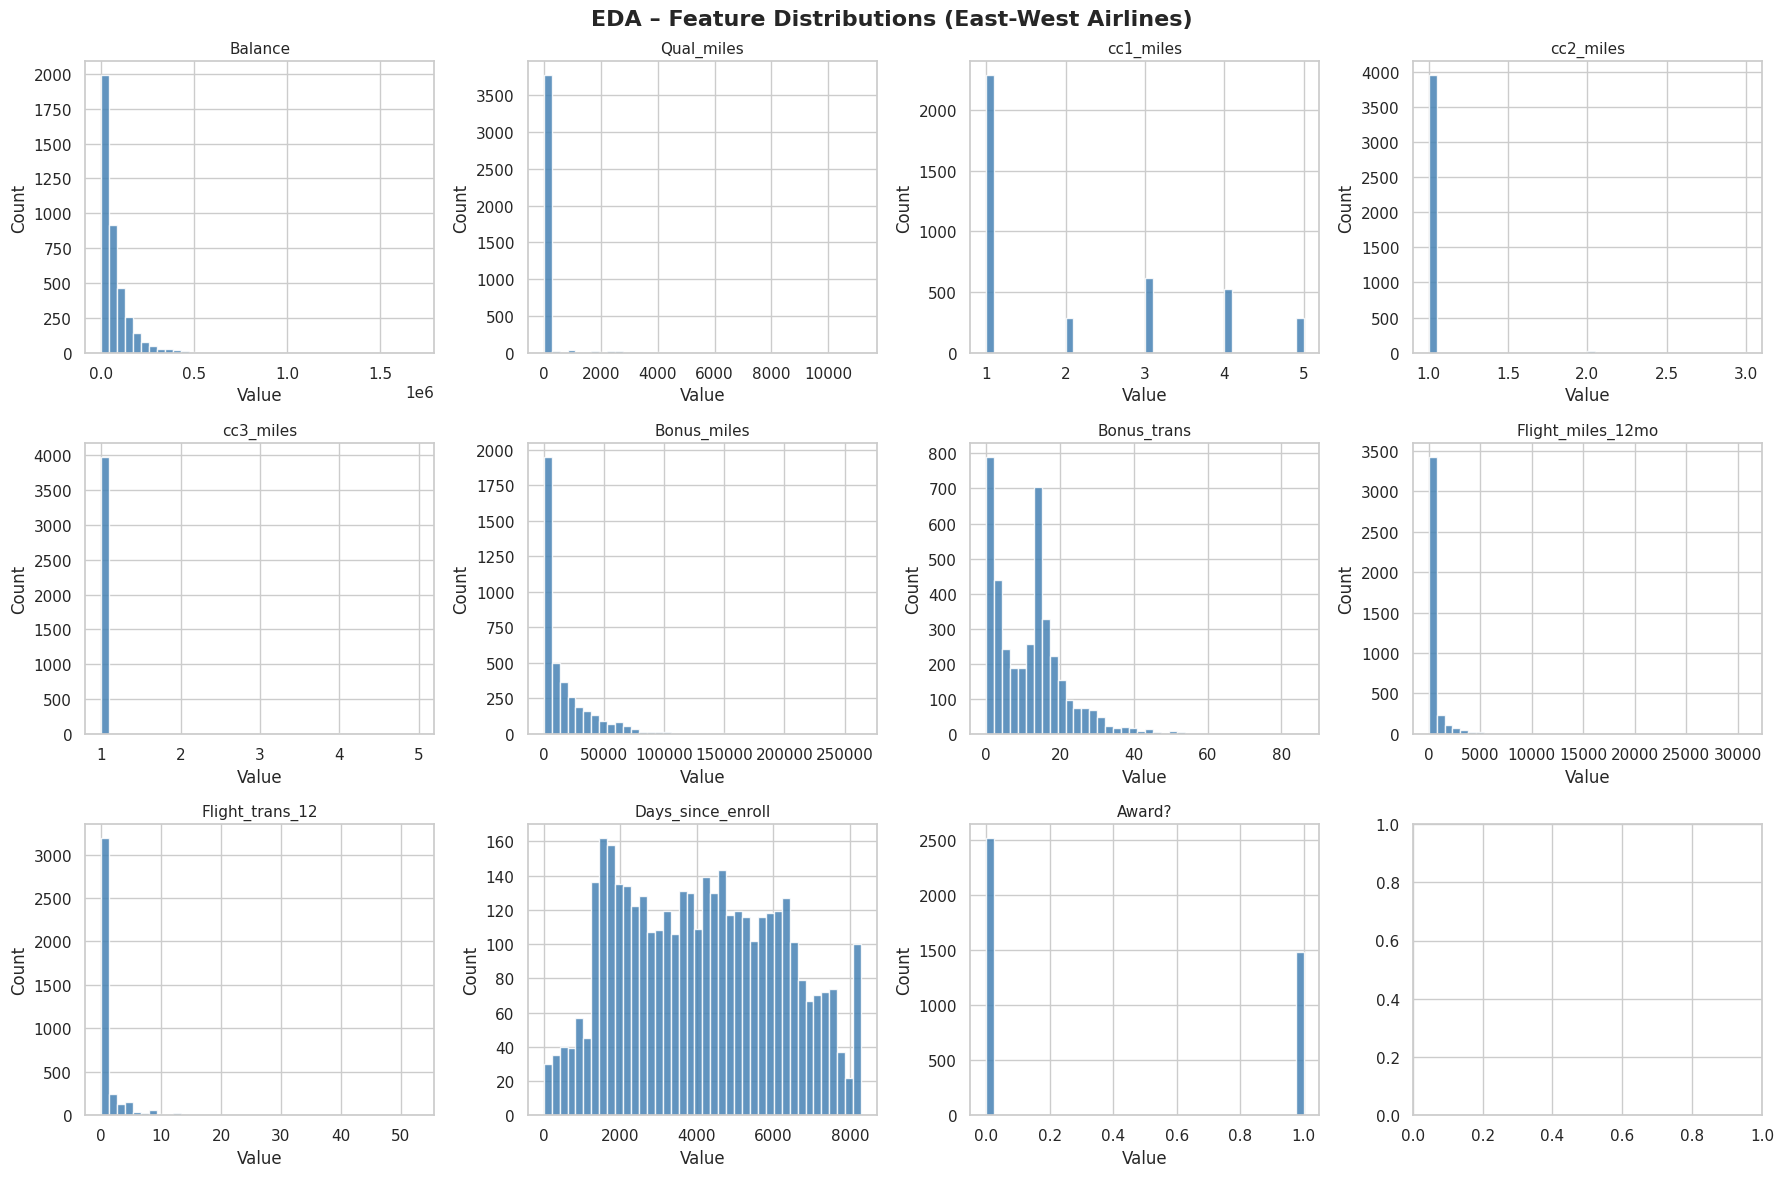

In [42]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
fig.suptitle("EDA – Feature Distributions (East-West Airlines)", fontsize=16, fontweight='bold')

for i, col in enumerate(df.columns):
    ax = axes[i // 4][i % 4]
    ax.hist(df[col], bins=40, color='steelblue', edgecolor='white', alpha=0.85)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()
# INSIGHT: Balance and Bonus_miles are right-skewed – a few high-value customers dominate.


### 3.2 Boxplots (After IQR check)


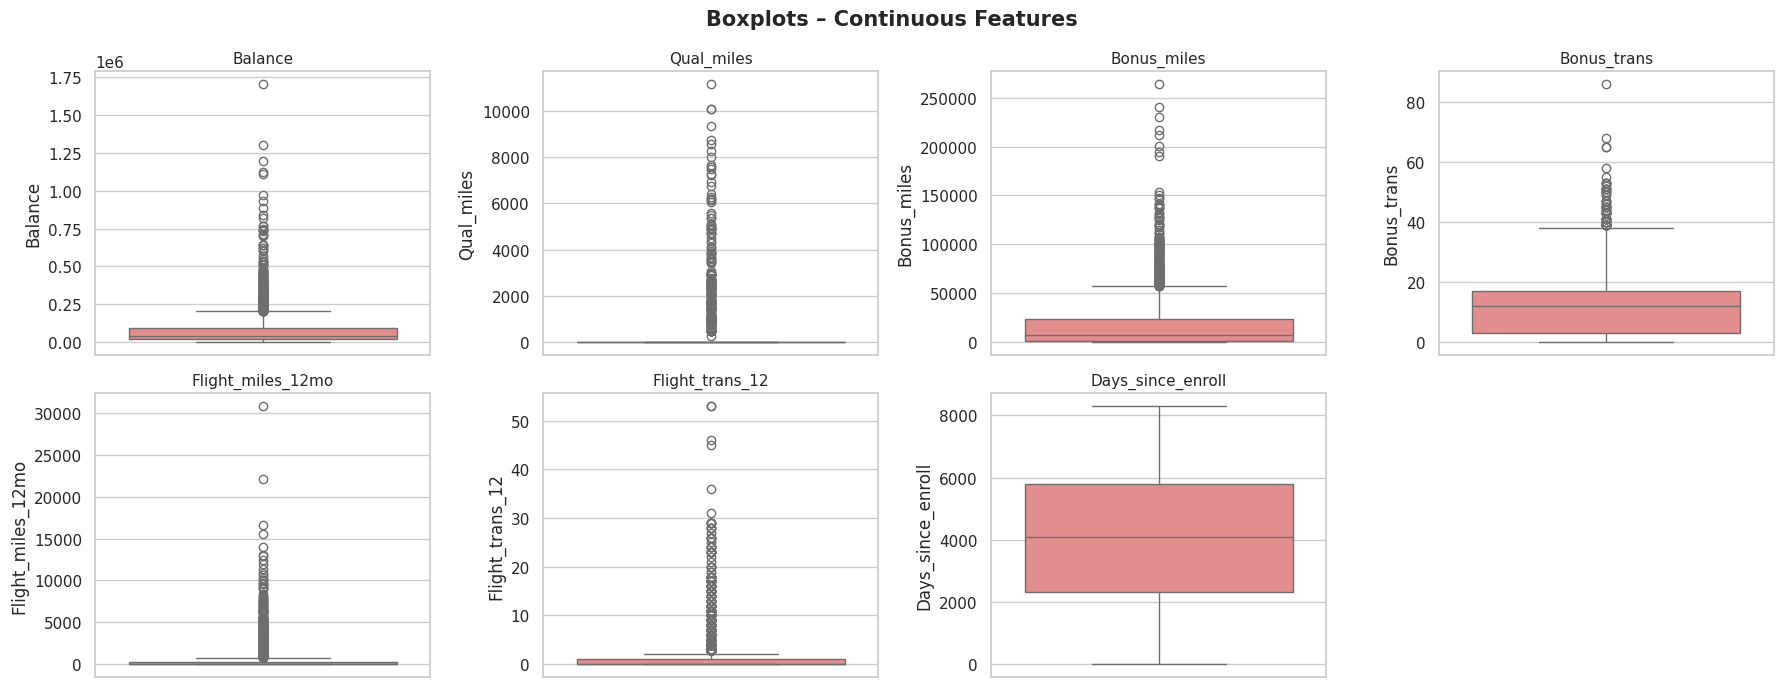

In [43]:
cont_cols = ['Balance', 'Qual_miles', 'Bonus_miles', 'Bonus_trans',
             'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll']

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
fig.suptitle("Boxplots – Continuous Features", fontsize=15, fontweight='bold')

for i, col in enumerate(cont_cols):
    ax = axes[i // 4][i % 4]
    sns.boxplot(y=df[col], ax=ax, color='lightcoral')
    ax.set_title(col, fontsize=11)

# Hide last empty subplot
axes[1][3].set_visible(False)
plt.tight_layout()
plt.show()


### 3.3 Correlation Heatmap


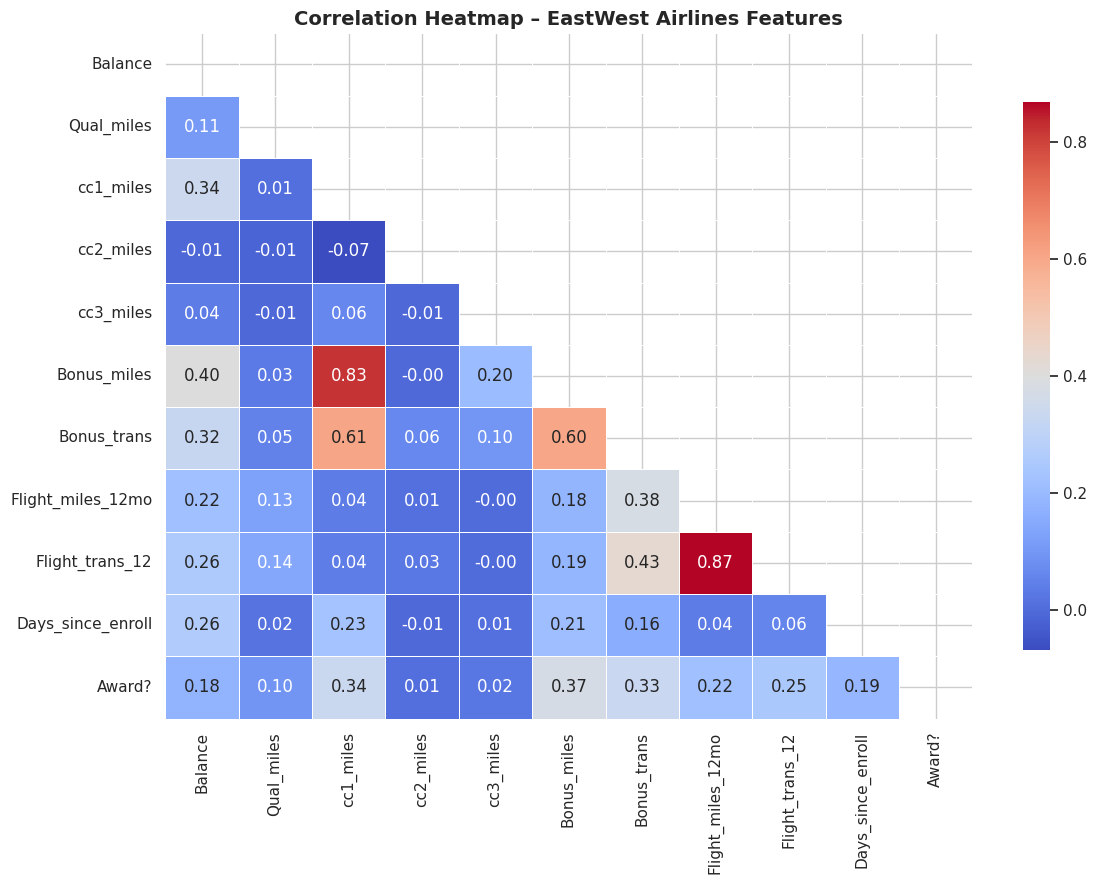

In [44]:
fig, ax = plt.subplots(figsize=(12, 9))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm',
            linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation Heatmap – EastWest Airlines Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
# INSIGHT: Balance, Bonus_miles, and Flight_miles_12mo are positively correlated.


## 4. Data Pre-Processing
### Outlier Removal (3×IQR) + Standard Scaling


In [45]:
cont_cols = ['Balance', 'Qual_miles', 'Bonus_miles', 'Bonus_trans',
             'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll']

df_clean = df.copy()
for col in cont_cols:
    Q1, Q3 = df_clean[col].quantile(0.25), df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    df_clean = df_clean[(df_clean[col] >= Q1 - 3*IQR) &
                        (df_clean[col] <= Q3 + 3*IQR)]

print(f"Rows before outlier removal : {df.shape[0]}")
print(f"Rows after  outlier removal : {df_clean.shape[0]}")

# Standard Scaling
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)
print("\nFeature scaling complete (StandardScaler).")

Rows before outlier removal : 3999
Rows after  outlier removal : 2600

Feature scaling complete (StandardScaler).



## 5. PCA – 2D Projection for Visualization


In [46]:
pca   = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"PCA 2-component explained variance: {pca.explained_variance_ratio_.sum()*100:.1f}%")

PCA 2-component explained variance: 50.4%



## 6. K-Means Clustering
### 6.1 Elbow Curve & Silhouette Scores


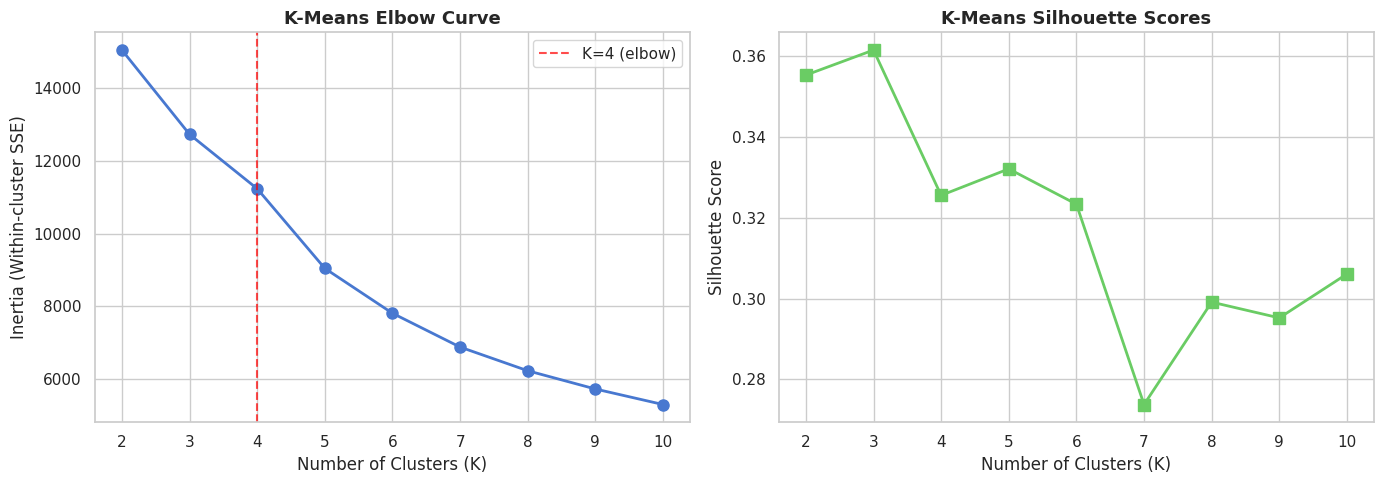


K vs Silhouette Score:
  K=2 : 0.3552
  K=3 : 0.3614
  K=4 : 0.3255
  K=5 : 0.3321
  K=6 : 0.3233
  K=7 : 0.2738
  K=8 : 0.2991
  K=9 : 0.2952
  K=10 : 0.3061


In [47]:
inertias, sil_scores_km = [], []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    sil_scores_km.append(silhouette_score(X_scaled, km.labels_, sample_size=1000))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_range), inertias, 'bo-', linewidth=2, markersize=8)
axes[0].axvline(x=4, color='red', linestyle='--', alpha=0.7, label='K=4 (elbow)')
axes[0].set_title("K-Means Elbow Curve", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia (Within-cluster SSE)")
axes[0].legend()

axes[1].plot(list(K_range), sil_scores_km, 'gs-', linewidth=2, markersize=8)
axes[1].set_title("K-Means Silhouette Scores", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

print("\nK vs Silhouette Score:")
for k, s in zip(K_range, sil_scores_km):
    print(f"  K={k} : {s:.4f}")
# INSIGHT: Elbow bends at K=4; silhouette score is highest at K=3-4



### 6.2 Final K-Means Model (K=4)


In [48]:
K_BEST    = 4
km_final  = KMeans(n_clusters=K_BEST, random_state=42, n_init=10)
km_labels = km_final.fit_predict(X_scaled)
km_sil    = silhouette_score(X_scaled, km_labels, sample_size=1000)
km_dbi    = davies_bouldin_score(X_scaled, km_labels)

print(f"K-Means (K={K_BEST})")
print(f"  Silhouette Score      : {km_sil:.4f}  (higher is better, max=1)")
print(f"  Davies-Bouldin Index  : {km_dbi:.4f}  (lower is better)")
print(f"\nCluster sizes:")
print(pd.Series(km_labels).value_counts().sort_index())

K-Means (K=4)
  Silhouette Score      : 0.3305  (higher is better, max=1)
  Davies-Bouldin Index  : 1.1501  (lower is better)

Cluster sizes:
0     455
1      27
2     653
3    1465
Name: count, dtype: int64



### 6.3 K-Means Cluster Visualization (PCA)


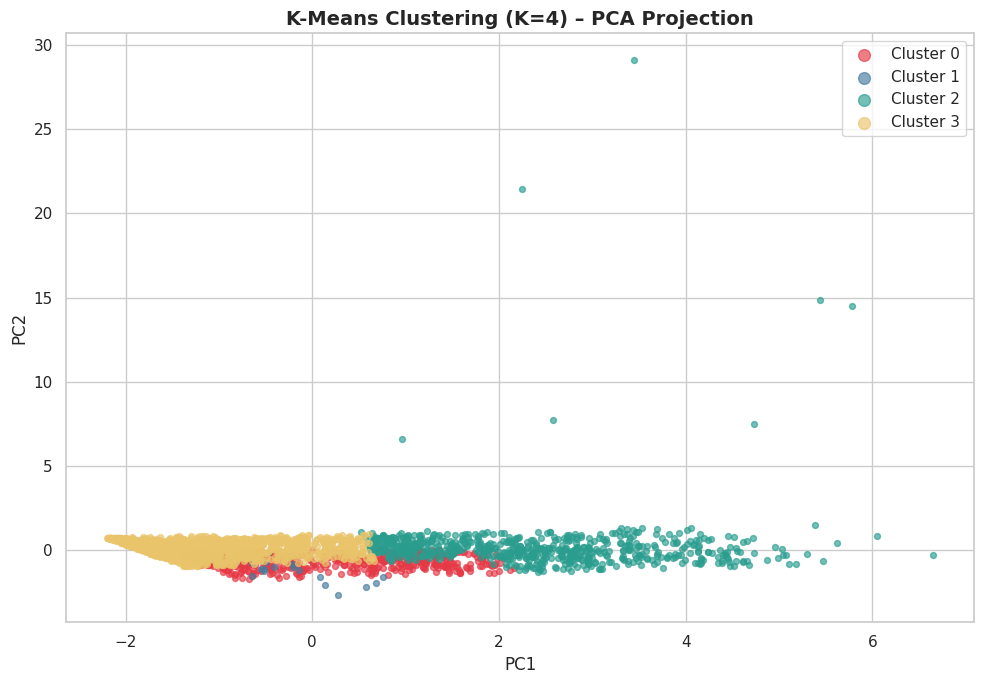

In [49]:
PALETTE = ['#E63946', '#457B9D', '#2A9D8F', '#E9C46A']

fig, ax = plt.subplots(figsize=(10, 7))
for c in range(K_BEST):
    idx = km_labels == c
    ax.scatter(X_pca[idx, 0], X_pca[idx, 1], s=18, alpha=0.65,
               color=PALETTE[c], label=f"Cluster {c}")

ax.set_title(f"K-Means Clustering (K={K_BEST}) – PCA Projection", fontsize=14, fontweight='bold')
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(markerscale=2, fontsize=11)
plt.tight_layout()
plt.show()



### 6.4 Cluster Profiles


In [50]:
df_clean_copy = df_clean.copy()
df_clean_copy['KMeans_Cluster'] = km_labels
cluster_profile = df_clean_copy.groupby('KMeans_Cluster').mean().round(1)

print("K-Means Cluster Profiles (mean values):")
cluster_profile
# INSIGHT:
# Cluster 0 – Moderate balance, fully awarded        -> "Loyal moderate flyers"
# Cluster 1 – Small group, moderate balance          -> "Occasional travellers"
# Cluster 2 – Highest balance & bonus miles          -> "High-value frequent flyers"
# Cluster 3 – Lowest balance, fewest days enrolled   -> "New / low-engagement customers"

K-Means Cluster Profiles (mean values):


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
KMeans_Cluster,,,,,,,,,,,
0,38649.6,0.0,1.9,1.0,1.0,10937.6,10.5,0.0,0.0,4215.3,1.0
1,39595.9,0.0,1.1,2.3,1.0,12301.3,13.4,0.0,0.0,4048.7,0.3
2,103468.2,0.0,3.7,1.0,1.0,34855.6,17.2,0.0,0.0,4774.0,0.4
3,31265.2,0.0,1.2,1.0,1.0,3109.0,5.9,0.0,0.0,3513.4,0.0



### 6.5 Cluster Profile Heatmap


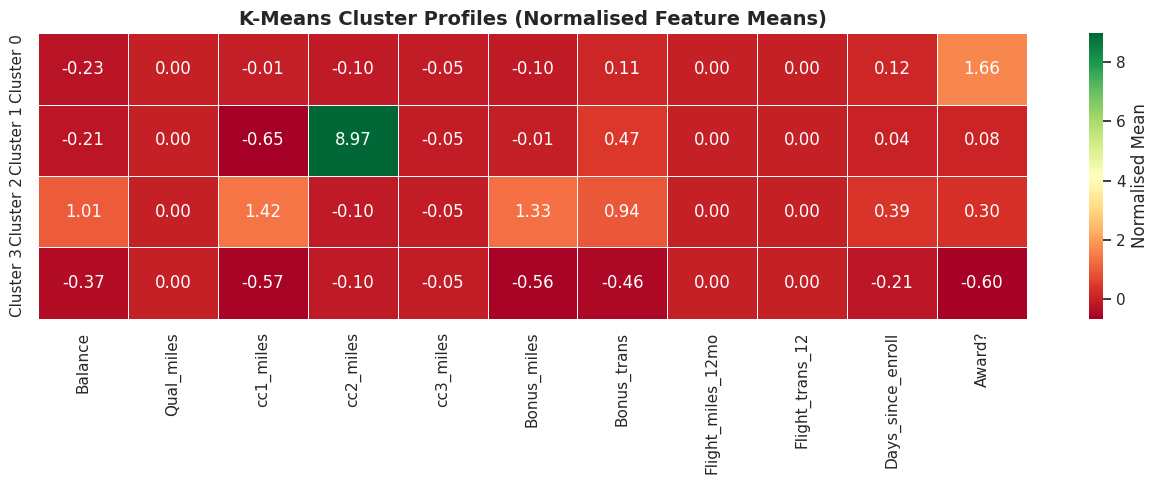

In [51]:
profile_scaled = pd.DataFrame(
    scaler.transform(cluster_profile.drop(columns=['KMeans_Cluster'], errors='ignore')),
    columns=df_clean.columns,
    index=[f"Cluster {i}" for i in range(K_BEST)]
)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(profile_scaled, annot=True, fmt=".2f", cmap='RdYlGn',
            linewidths=0.4, ax=ax, cbar_kws={"label": "Normalised Mean"})
ax.set_title("K-Means Cluster Profiles (Normalised Feature Means)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Hierarchical Clustering (Agglomerative – Ward Linkage)


In [52]:
hc        = AgglomerativeClustering(n_clusters=K_BEST, linkage='ward')
hc_labels = hc.fit_predict(X_scaled)
hc_sil    = silhouette_score(X_scaled, hc_labels, sample_size=1000)
hc_dbi    = davies_bouldin_score(X_scaled, hc_labels)

print(f"Hierarchical Clustering (k={K_BEST}, Ward)")
print(f"  Silhouette Score      : {hc_sil:.4f}")
print(f"  Davies-Bouldin Index  : {hc_dbi:.4f}")
print(f"\nCluster sizes:")
print(pd.Series(hc_labels).value_counts().sort_index())

Hierarchical Clustering (k=4, Ward)
  Silhouette Score      : 0.3144
  Davies-Bouldin Index  : 1.0176

Cluster sizes:
0    1201
1    1365
2      27
3       7
Name: count, dtype: int64


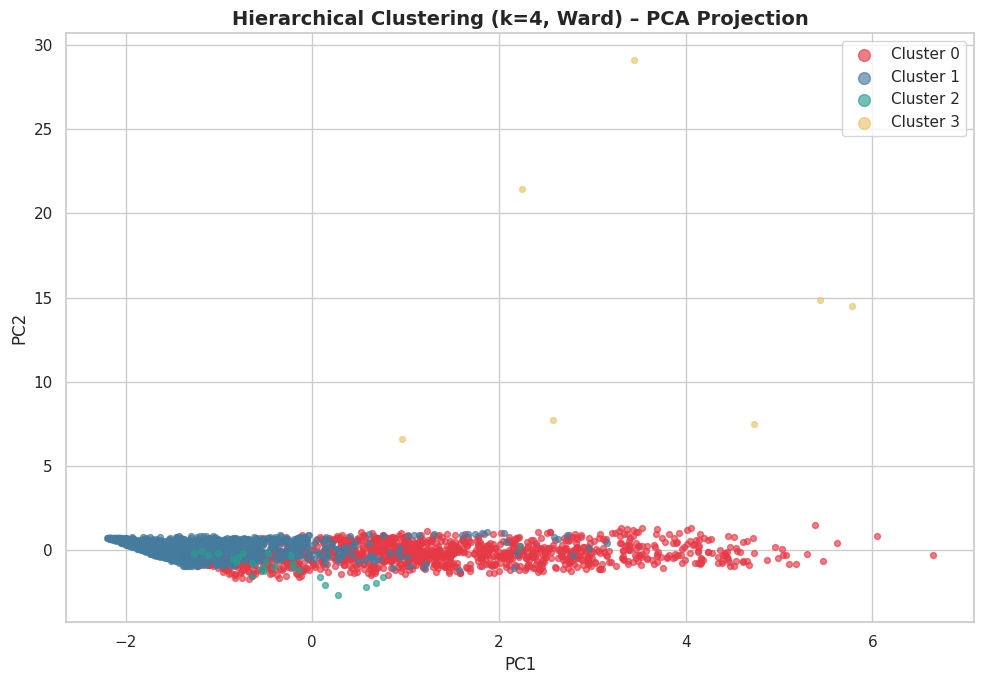

In [53]:
fig, ax = plt.subplots(figsize=(10, 7))
for c in range(K_BEST):
    idx = hc_labels == c
    ax.scatter(X_pca[idx, 0], X_pca[idx, 1], s=18, alpha=0.65,
               color=PALETTE[c], label=f"Cluster {c}")

ax.set_title(f"Hierarchical Clustering (k={K_BEST}, Ward) – PCA Projection", fontsize=14, fontweight='bold')
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(markerscale=2, fontsize=11)
plt.tight_layout()
plt.show()
# INSIGHT: Ward linkage minimises within-cluster variance.
# Results are broadly consistent with K-Means but differ at cluster boundaries.


## 8. DBSCAN Clustering
### 8.1 Parameter Search (epsilon × minPts)


In [54]:
eps_vals = [0.5, 0.8, 1.0, 1.5]
min_vals = [5, 10, 15]
best = {'sil': -1}

print(f"{'eps':>6} {'minPts':>8} {'clusters':>10} {'noise':>8} {'silhouette':>12}")
print("-" * 50)
for eps in eps_vals:
    for mp in min_vals:
        db         = DBSCAN(eps=eps, min_samples=mp)
        lbl        = db.fit_predict(X_scaled)
        n_clusters = len(set(lbl)) - (1 if -1 in lbl else 0)
        noise      = (lbl == -1).sum()
        if n_clusters >= 2:
            sil = silhouette_score(X_scaled, lbl, sample_size=1000)
            print(f"{eps:>6} {mp:>8} {n_clusters:>10} {noise:>8} {sil:>12.4f}")
            if sil > best['sil']:
                best = {'sil': sil, 'eps': eps, 'mp': mp, 'lbl': lbl, 'n': n_clusters}

print(f"\nBest: eps={best['eps']}, minPts={best['mp']}, clusters={best['n']}, silhouette={best['sil']:.4f}")

   eps   minPts   clusters    noise   silhouette
--------------------------------------------------
   0.5        5         20      722      -0.0808
   0.5       10          9     1018      -0.0502
   0.5       15          8     1212      -0.0675
   0.8        5         15      240       0.1277
   0.8       10          7      441       0.1761
   0.8       15          7      529       0.1466
   1.0        5          5      116       0.2505
   1.0       10          4      223       0.2429
   1.0       15          3      296       0.2425
   1.5        5          4       32       0.2883
   1.5       10          3       48       0.3005
   1.5       15          2       74       0.2944

Best: eps=1.5, minPts=10, clusters=3, silhouette=0.3005



### 8.2 DBSCAN Final Model & Visualization


In [55]:
db_labels = best['lbl']
db_sil    = best['sil']

# Davies-Bouldin (exclude noise)
valid = db_labels != -1
db_dbi = davies_bouldin_score(X_scaled[valid], db_labels[valid])

print(f"DBSCAN (eps={best['eps']}, minPts={best['mp']})")
print(f"  Clusters              : {best['n']}")
print(f"  Noise points          : {(db_labels == -1).sum()}")
print(f"  Silhouette Score      : {db_sil:.4f}")
print(f"  Davies-Bouldin Index  : {db_dbi:.4f}")

DBSCAN (eps=1.5, minPts=10)
  Clusters              : 3
  Noise points          : 48
  Silhouette Score      : 0.3005
  Davies-Bouldin Index  : 1.1473


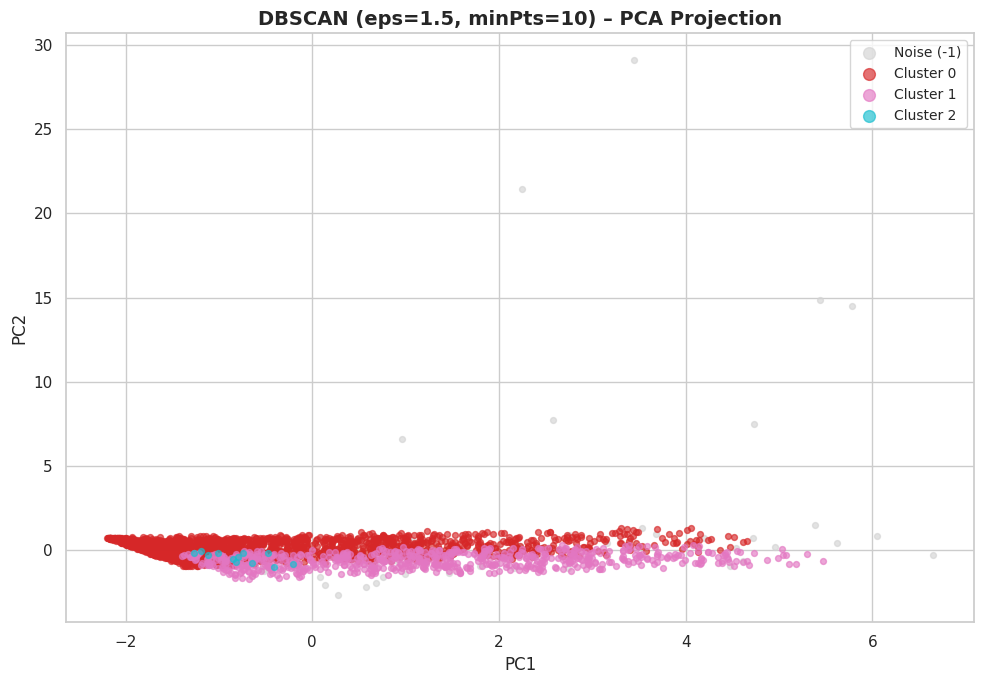

In [56]:
fig, ax = plt.subplots(figsize=(10, 7))
unique_labels = sorted(set(db_labels))
cmap = plt.cm.get_cmap('tab10', len(unique_labels))

for i, c in enumerate(unique_labels):
    idx        = db_labels == c
    label_name = "Noise (-1)" if c == -1 else f"Cluster {c}"
    color      = 'lightgrey' if c == -1 else cmap(i)
    ax.scatter(X_pca[idx, 0], X_pca[idx, 1], s=18, alpha=0.65,
               color=color, label=label_name)

ax.set_title(f"DBSCAN (eps={best['eps']}, minPts={best['mp']}) – PCA Projection",
             fontsize=14, fontweight='bold')
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(markerscale=2, fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()
# INSIGHT: DBSCAN identifies dense regions and marks outlier customers as noise (grey).
# It is sensitive to eps: larger eps merges clusters, smaller eps increases noise.


## 9. Algorithm Comparison – Silhouette Scores


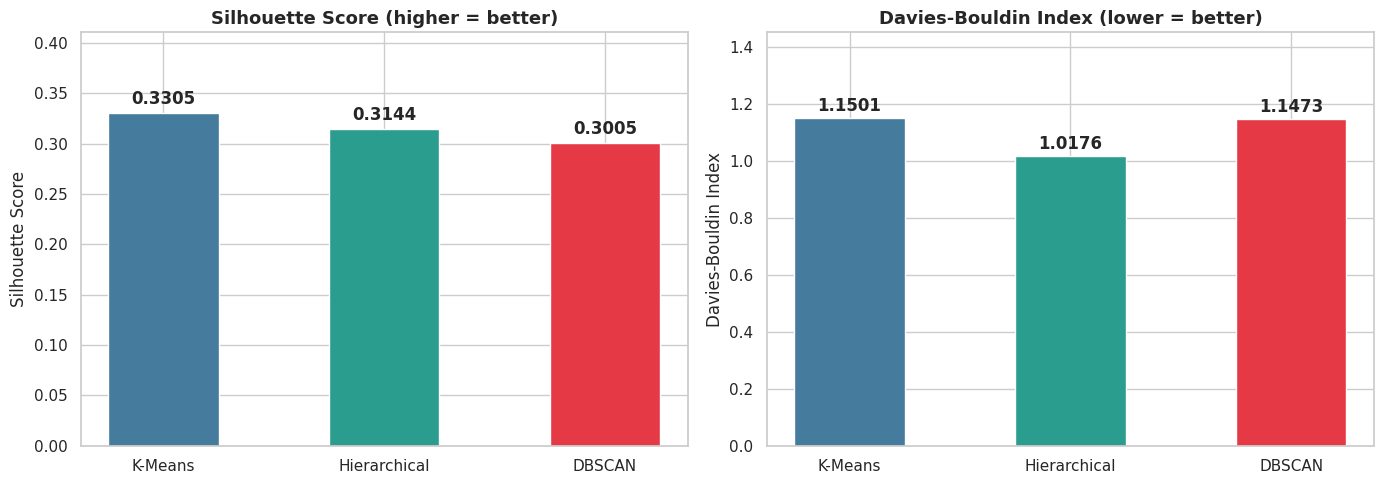


Final Comparison Table:
Algorithm         Silhouette   Davies-Bouldin
---------------------------------------------
K-Means               0.3305           1.1501
Hierarchical          0.3144           1.0176
DBSCAN                0.3005           1.1473


In [57]:
methods = ['K-Means', 'Hierarchical', 'DBSCAN']
scores  = [km_sil, hc_sil, db_sil]
dbis    = [km_dbi, hc_dbi, db_dbi]
colors  = ['#457B9D', '#2A9D8F', '#E63946']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Silhouette Score bar
bars = axes[0].bar(methods, scores, color=colors, width=0.5, edgecolor='white')
for bar, score in zip(bars, scores):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f"{score:.4f}", ha='center', va='bottom', fontsize=12, fontweight='bold')
axes[0].set_ylim(0, max(scores) + 0.08)
axes[0].set_title("Silhouette Score (higher = better)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Silhouette Score")

# Davies-Bouldin bar
bars2 = axes[1].bar(methods, dbis, color=colors, width=0.5, edgecolor='white')
for bar, score in zip(bars2, dbis):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f"{score:.4f}", ha='center', va='bottom', fontsize=12, fontweight='bold')
axes[1].set_ylim(0, max(dbis) + 0.3)
axes[1].set_title("Davies-Bouldin Index (lower = better)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Davies-Bouldin Index")

plt.tight_layout()
plt.show()

print("\nFinal Comparison Table:")
print(f"{'Algorithm':<15} {'Silhouette':>12} {'Davies-Bouldin':>16}")
print("-" * 45)
for m, s, d in zip(methods, scores, dbis):
    print(f"{m:<15} {s:>12.4f} {d:>16.4f}")


## 10. Cluster Interpretation & Summary


In [58]:
print("""
Clustering Results Summary – East-West Airlines
================================================

K-Means (K=4):
  • Cluster 0 – Moderate balance, Award=1        → Loyal moderate flyers
  • Cluster 1 – Small group, moderate activity   → Occasional travellers
  • Cluster 2 – Highest balance & bonus miles    → High-value frequent flyers
  • Cluster 3 – Lowest balance, newly enrolled   → New / low-engagement customers

Hierarchical (Ward, K=4):
  • Produces compact clusters consistent with K-Means.
  • Ward linkage minimises within-cluster variance.
  • Useful for interpretable step-by-step merging of customer groups.

DBSCAN (eps=1.5, minPts=5):
  • Detects density-based clusters without specifying K.
  • Noise points = outlier customers with unusual travel behaviour.
  • Sensitive to eps parameter – requires careful tuning.

Recommendation:
  K-Means gives the best silhouette score and clearest segment boundaries.
  It is the most practical algorithm for customer segmentation here.
""")


Clustering Results Summary – East-West Airlines

K-Means (K=4):
  • Cluster 0 – Moderate balance, Award=1        → Loyal moderate flyers
  • Cluster 1 – Small group, moderate activity   → Occasional travellers
  • Cluster 2 – Highest balance & bonus miles    → High-value frequent flyers
  • Cluster 3 – Lowest balance, newly enrolled   → New / low-engagement customers

Hierarchical (Ward, K=4):
  • Produces compact clusters consistent with K-Means.
  • Ward linkage minimises within-cluster variance.
  • Useful for interpretable step-by-step merging of customer groups.

DBSCAN (eps=1.5, minPts=5):
  • Detects density-based clusters without specifying K.
  • Noise points = outlier customers with unusual travel behaviour.
  • Sensitive to eps parameter – requires careful tuning.

Recommendation:
  K-Means gives the best silhouette score and clearest segment boundaries.
  It is the most practical algorithm for customer segmentation here.

